# 03 · Backtest results

Rolling-origin evaluation inside the 110-point training window: 13 origins (every 15 min from t=48), each forecasting 24 steps ahead. Every model sees the same origins. The holdout comes in only at the end, scored once.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..") if Path("../challenge_data").exists() else Path(".")
DATA, FIG = ROOT / "challenge_data", ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)
from cwfc.config import Config
from cwfc.predict import forecast_target, holdout_report
from cwfc.train import prepare, select

cfg, train, holdout = prepare(DATA, Config(data_dir=DATA), verbose=False)
selections = select(train, cfg)
for t, s in selections.items():
    print(t, "->", s.model, "| origins:", s.origins)

active_vm_count -> persistence | origins: [48, 51, 54, 57, 60, 63, 66, 69, 72, 75, 78, 81, 84]
aggregate_cpu_utilization -> ets_seasonal_12 | origins: [48, 51, 54, 57, 60, 63, 66, 69, 72, 75, 78, 81, 84]


## Metric tables

In [2]:
selections["active_vm_count"].summary

,mae,rmse,mase,peak_mae,worst_fold_mae,mae_vs_baseline_pct
model,,,,,,
persistence,0.0,0.0,0.0,0.0,0.0,0.0
mean_6,0.0,0.0,0.0,0.0,0.0,0.0
mean_12,0.0,0.0,0.0,0.0,0.0,0.0
drift,0.0,0.0,0.0,0.0,0.0,0.0
seasonal_naive_12,0.0,0.0,0.0,0.0,0.0,0.0
level_season_12,0.0,0.0,0.0,0.0,0.0,0.0
holt_damped,0.0,0.0,0.0,0.0,0.0,0.0
ets_seasonal_12,0.0,0.0,0.0,0.0,0.0,0.0
arima_aic,0.0,0.0,0.0,0.0,0.0,0.0


Every model scores zero error on `active_vm_count` because the series is constant. The tie goes to persistence, the simplest model.

In [3]:
cpu = selections["aggregate_cpu_utilization"]
cpu.summary.sort_values("mase")

,mae,rmse,mase,peak_mae,worst_fold_mae,mae_vs_baseline_pct
model,,,,,,
ets_seasonal_12,0.227,0.282,1.817,0.243,0.401,11.953
arima_aic,0.242,0.296,1.937,0.272,0.392,6.079
mean_6,0.250,0.300,2.002,0.251,0.372,3.030
persistence,0.258,0.315,2.057,0.206,0.474,0.000
ridge_direct,0.259,0.316,2.071,0.292,0.532,-0.675
level_season_12,0.268,0.306,2.145,0.265,0.400,-4.139
mean_12,0.270,0.313,2.162,0.267,0.400,-4.946
holt_damped,0.276,0.337,2.209,0.258,0.454,-7.106
seasonal_naive_12,0.286,0.333,2.287,0.305,0.400,-10.969


The seasonal ETS (additive level + additive 12-step season) wins on MAE, RMSE and MASE, about 12% better than persistence on MAE. ARIMA comes second. Persistence is still the best on **peak MAE**. Model-based forecasts smooth toward the level, so they under-call the high points, and the capacity rule has to correct for that. MASE is above 1 for every model because it scales 24-step errors by a one-step naive error.

## Error by horizon

model,persistence,mean_6,arima_aic,ets_seasonal_12
step,,,,
1,0.108,0.109,0.107,0.097
6,0.168,0.177,0.189,0.167
12,0.222,0.262,0.253,0.230
18,0.288,0.259,0.244,0.278
24,0.263,0.231,0.206,0.262


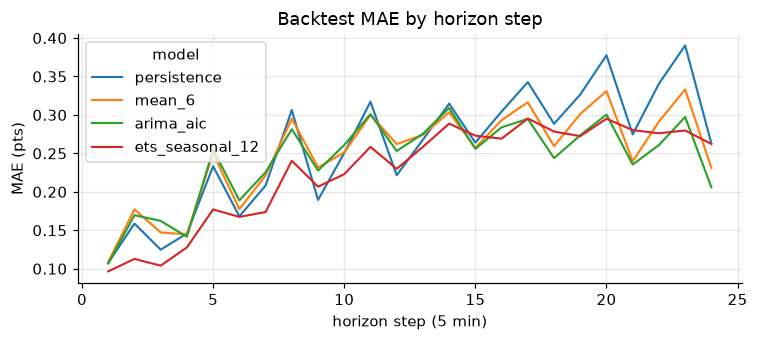

In [4]:
show = ["persistence", "mean_6", "arima_aic", cpu.model]
res = cpu.results
by_step = res[res["model"].isin(show)].assign(ae=lambda d: d["error"].abs()).pivot_table(index="step", columns="model", values="ae")
fig, ax = plt.subplots(figsize=(7, 3.2))
by_step[show].plot(ax=ax, lw=1.4)
ax.set_xlabel("horizon step (5 min)"); ax.set_ylabel("MAE (pts)"); ax.set_title("Backtest MAE by horizon step")
fig.tight_layout(); fig.savefig(FIG / "error_by_horizon.png")
by_step.iloc[[0, 5, 11, 17, 23]][show]

The seasonal ETS has the lowest error at nearly every step up to about 75 minutes. Its error rises from 0.10 pts at 5 minutes to about 0.27 by the end of the first hour, then stays flat. The series reverts to a level instead of trending away, so the second hour costs little extra accuracy. The saw-tooth pattern in the baselines is the hourly spike landing on different steps in different folds, since origins are 15 minutes apart.

## Worst fold

origin              48     51     54     57     60     63     66     69  \
ets_seasonal_12  0.341  0.296  0.228  0.238  0.270  0.275  0.354  0.401   
persistence      0.298  0.233  0.160  0.263  0.305  0.302  0.464  0.474   

origin              72     75     78     81     84  
ets_seasonal_12  0.225  0.073  0.110  0.063  0.075  
persistence      0.257  0.089  0.257  0.131  0.118  


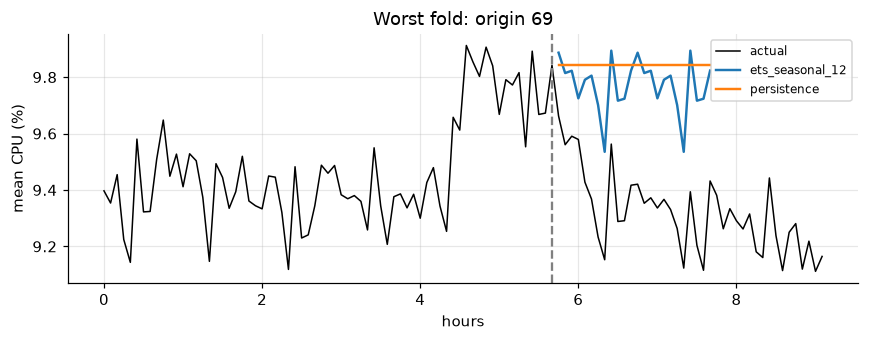

In [5]:
fold = res[res["model"] == cpu.model].groupby("origin").apply(lambda f: f["error"].abs().mean(), include_groups=False)
naive_fold = res[res["model"] == "persistence"].groupby("origin").apply(lambda f: f["error"].abs().mean(), include_groups=False)
print(pd.DataFrame({cpu.model: fold, "persistence": naive_fold}).round(3).T)
worst = int(fold.idxmax())
y = train.set_index("timestamp")["aggregate_cpu_utilization"]
w = res[(res["origin"] == worst) & res["model"].isin([cpu.model, "persistence"])]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(y.index / 3600, y.to_numpy(), c="k", lw=1, label="actual")
for name, g in w.groupby("model"):
    ax.plot(g["timestamp"] / 3600, g["forecast"], lw=1.6, label=name)
ax.axvline(y.index[worst - 1] / 3600, ls="--", c="grey")
ax.set_xlabel("hours"); ax.set_ylabel("mean CPU (%)"); ax.set_title(f"Worst fold: origin {worst}"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "worst_fold.png")

The worst folds (origins 66–69) start while the series is still in the elevated batch period and must forecast the drop back to normal. Nothing available at the origin signals that the batch block is about to end, so every univariate model, including persistence, misses it. Fixing this would take job-schedule information, not a better curve fit.

## Uncertainty bands

In [6]:
from cwfc.intervals import residual_quantiles
q = residual_quantiles(cpu.errors, cfg.horizon)
err = cpu.errors.merge(q, left_on="step", right_index=True)
for p in [0.9, 0.95]:
    print(f"backtest share of actuals under the p{int(p*100)} band:", round((err["error"] <= err[p]).mean(), 3))
q.iloc[[0, 5, 11, 23]]

backtest share of actuals under the p90 band: 0.894
backtest share of actuals under the p95 band: 0.939


,0.10,0.90,0.95
1,-0.177,0.144,0.195
6,-0.248,0.308,0.447
12,-0.422,0.365,0.429
24,-0.494,0.048,0.214


Bands come from per-step quantiles of backtest errors, pooled over ±2 neighbouring steps. In-sample coverage is close to nominal by construction. The late-step quantiles are skewed (forecasts ran high after the batch bump ended), which is a reminder that 13 overlapping folds are a small sample.

## Capacity rules on the backtest

Three candidate provisioning rules, all built from backtest errors only: the per-step p95 band, a flat line at the band's maximum over the 2-hour window (one scaling decision per window), and persistence plus a static p95 margin.

In [7]:
from cwfc.intervals import backtest_policies, policy_stats
policies = backtest_policies(cpu.results, cpu.model, cfg.horizon)
policies

,breach_rate,mean_headroom,worst_shortfall,window_breach_rate
per_step_band,0.061,0.471,0.301,0.231
block_max_band,0.000,0.695,0.000,0.000
persistence_static_margin,0.051,0.510,0.180,0.154


The per-step band breaches 6% of timestamps, and 23% of 2-hour windows have at least one breach because every step gets its own 5% chance. A flat line at the window's maximum band removes every backtest breach. It costs about 0.22 pts more average headroom (0.70 vs 0.47), roughly 60 vCPUs at ~284 vCPUs per point. A static p95 margin on persistence falls between the two: 5% of timestamps, 15% of windows, 0.51 headroom. The seasonal model improves point accuracy more than it improves the tail. These numbers are in-sample, since the quantiles come from the same folds.

## Holdout (scored once, after everything above was fixed)

In [8]:
bands = {t: forecast_target(train, s, cfg) for t, s in selections.items()}
preds = pd.DataFrame({"timestamp": holdout["timestamp"].to_numpy()})
for t in bands:
    preds[t] = bands[t]["forecast"].to_numpy()
report = holdout_report(preds, bands, selections, train, holdout)
report

,model,mae,rmse,persistence_mae,persistence_rmse,coverage_p90,coverage_p95
target,,,,,,,
active_vm_count,persistence,0.00,0.000,0.000,0.000,1.000,1.000
aggregate_cpu_utilization,ets_seasonal_12,0.14,0.176,0.147,0.185,0.875,0.875


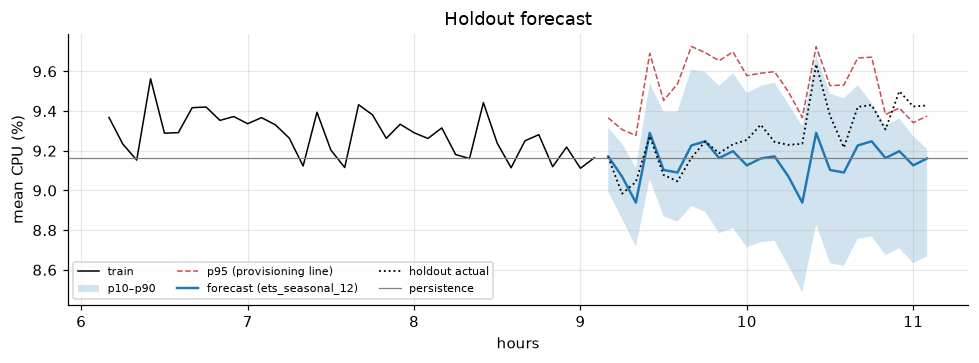

In [9]:
b = bands["aggregate_cpu_utilization"]
hx = holdout["timestamp"] / 3600
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(y.index[-36:] / 3600, y.to_numpy()[-36:], c="k", lw=1, label="train")
ax.fill_between(hx, b["p10"], b["p90"], alpha=0.2, label="p10–p90")
ax.plot(hx, b["p95"], ls="--", c="#c44e52", lw=1, label="p95 (provisioning line)")
ax.plot(hx, b["forecast"], lw=1.6, label=f"forecast ({cpu.model})")
ax.plot(hx, holdout["aggregate_cpu_utilization"], c="k", ls=":", lw=1.2, label="holdout actual")
ax.axhline(y.iloc[-1], c="grey", lw=0.8, label="persistence")
ax.set_xlabel("hours"); ax.set_ylabel("mean CPU (%)"); ax.legend(fontsize=7, ncol=3, loc="lower left")
ax.set_title("Holdout forecast")
fig.tight_layout(); fig.savefig(FIG / "holdout_forecast.png")

In [10]:
actual = holdout["aggregate_cpu_utilization"].to_numpy()
last = train["aggregate_cpu_utilization"].iloc[-1]
margin = res.loc[res["model"] == "persistence", "error"].quantile(0.95)
pd.DataFrame({
    "per_step_band": policy_stats(actual, b["p95"]),
    "block_max_band": policy_stats(actual, np.full(len(actual), b["p95"].max())),
    "persistence_static_margin": policy_stats(actual, np.full(len(actual), last + margin)),
}).T

,breach_rate,mean_headroom,worst_shortfall
per_step_band,0.125,0.259,0.085
block_max_band,0.000,0.456,0.000
persistence_static_margin,0.042,0.243,0.124


On the holdout, the block rule again has no breaches with 0.46 pts mean headroom. The per-step band breaches 3 of 24 steps and the static margin breaches 1.

On the holdout the seasonal ETS beats persistence by about 5% on MAE and RMSE, a smaller margin than in the backtest. The holdout happens to be calm, and that favours persistence. The per-step p95 band covers 21 of 24 points (87.5%), below nominal. With 13 overlapping folds the error quantiles are a little optimistic. The block rule chosen above on backtest evidence is scored below as-is; nothing was adjusted after seeing these numbers.